# Proyecto: Análisis y Predicción de Emisiones de $CO_2$ Vehiculares

**Materia:** Laboratorio de Aprendizaje Estadístico  
**Alumno:** Abraham Casarrubias Rosales  

---

## 1. Objetivos

### Objetivo General
Predecir las emisiones de $CO_2$ de los vehículos basándonos en sus características técnicas, hábitos de manejo y contexto ambiental mediante modelos de regresión lineal y regularizada.

### Objetivos Específicos
* **Analizar y preparar los datos:** Realizar la limpieza, transformación de variables categóricas y escalamiento de variables numéricas.
* **Construir y ajustar los modelos:** Implementar 3 arquitecturas de modelos de regresión con sus 4 variantes cada una (Sin penalización, Ridge, Lasso y ElasticNet).
* **Evaluación de desempeño:** Comparar el rendimiento de los 12 modelos ajustados mediante la métrica $R^2$ y el error cuadrático medio (RMSE).
* **Evaluar la significancia de los factores:** Identificar mediante el valor $p$ qué variables tienen un impacto real en las emisiones de $CO_2$.

---

## 2. Marco Teórico

* **Regresión Lineal Simple y Múltiple:** Modelo estadístico que asume una relación lineal entre las variables explicativas y la variable respuesta.
* **Regresión Polinomial:** Extensión de la regresión lineal que captura relaciones no lineales elevando las variables a potencias.
* **Interacción de Factores:** Ocurre cuando el efecto de una variable sobre la respuesta depende del nivel de otra variable.
* **Significancia de Factores ($p$-value):** Mide la probabilidad de que la relación observada entre una variable y la respuesta sea fruto del azar.
* **Regularización:**
  * **Ridge ($L_2$):** Suma la magnitud al cuadrado de los coeficientes como término de penalización para mitigar la multicolinealidad.
  * **Lasso ($L_1$):** Suma el valor absoluto de los coeficientes, permitiendo reducir coeficientes a cero para selección de variables.
  * **ElasticNet:** Combina las penalizaciones $L_1$ y $L_2$.

### 6 Errores Comunes en Regresión:
1. No linealidad en los datos.
2. Correlación de errores (Autocorrelación).
3. Varianza no constante (Heterocedasticidad).
4. Outliers en la variable respuesta $Y$.
5. Puntos con alto apalancamiento (Valores palanca en $X$).
6. Multicolinealidad entre variables explicativas.

## Código

Librerias

In [171]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error
import statsmodels.api as sm

Cargar DataSet

In [172]:
CO2 = pd.read_csv(r"C:\Users\user\Documents\ITESO\5 SEMESTRE\Laboratorio de aprendizaje estadistico\Proyecto\vehicle_emission_dataset.csv.zip").replace("\\", "/")

Ver DataSet

In [173]:
CO2.describe()

,Engine Size,Age of Vehicle,Mileage,Speed,Acceleration,Temperature,Humidity,Wind Speed,Air Pressure,CO2 Emissions,NOx Emissions,PM2.5 Emissions,VOC Emissions,SO2 Emissions
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,3.369630,14.490000,148995.708000,59.448818,2.491924,14.935772,50.144758,10.027946,1000.199354,273.747254,1.043678,0.105300,0.054611,0.055105
std,1.495677,8.584339,87068.385915,34.437175,1.446130,14.432900,28.787763,5.735533,28.789590,130.789943,0.548226,0.054933,0.025971,0.026076
min,0.800061,0.000000,56.000000,0.000664,0.000084,-9.995320,0.000843,0.003425,950.013001,50.045412,0.100056,0.010005,0.010005,0.010005
25%,2.080910,7.000000,73589.750000,29.502708,1.245908,2.331247,25.731917,5.060126,975.096398,158.448360,0.565941,0.057322,0.031919,0.032710
50%,3.361149,15.000000,148914.500000,59.701114,2.482625,15.013688,49.947395,10.052823,1000.787886,274.734257,1.047428,0.105113,0.054669,0.054948
75%,4.648033,22.000000,224359.500000,88.499982,3.747481,27.423980,75.273523,15.044782,1025.092893,387.958329,1.513206,0.153704,0.076847,0.077687
max,5.998532,29.000000,299863.000000,119.974725,4.999861,39.997848,99.993970,19.997502,1049.986720,499.996419,1.999954,0.199957,0.099993,0.099980


In [174]:
CO2.columns

Index(['Vehicle Type', 'Fuel Type', 'Engine Size', 'Age of Vehicle', 'Mileage',
       'Speed', 'Acceleration', 'Road Type', 'Traffic Conditions',
       'Temperature', 'Humidity', 'Wind Speed', 'Air Pressure',
       'CO2 Emissions', 'NOx Emissions', 'PM2.5 Emissions', 'VOC Emissions',
       'SO2 Emissions', 'Emission Level'],
      dtype='str')

In [175]:
CO2_original=CO2.copy
CO2=CO2.drop(columns=['NOx Emissions','PM2.5 Emissions','VOC Emissions','SO2 Emissions',"Emission Level"
                        ])
CO2.head()


,Vehicle Type,Fuel Type,Engine Size,Age of Vehicle,Mileage,Speed,Acceleration,Road Type,Traffic Conditions,Temperature,Humidity,Wind Speed,Air Pressure,CO2 Emissions
0,Motorcycle,Electric,2.747609,22,291288,49.083255,1.887738,Highway,Moderate,13.880458,52.883905,18.938861,955.411642,179.930088
1,Bus,Electric,5.743714,3,188398,23.460311,3.544147,City,Heavy,19.136947,5.697343,14.716526,1035.763062,250.505219
2,Bus,Hybrid,4.606368,17,281451,115.508350,4.646886,Highway,Free flow,8.123428,3.953116,18.644522,976.207064,404.979103
3,Truck,Electric,3.913024,4,151321,18.540217,3.581004,Rural,Heavy,35.994893,0.509678,11.951859,966.919462,463.568608
4,Truck,Hybrid,1.611297,15,91810,109.596566,3.879303,Highway,Moderate,14.793481,52.450884,2.761138,953.229351,79.514604


* **Variables Numéricas:** `Engine Size`, `Age of Vehicle`, `Mileage`, `Speed`, `Acceleration`, `Temperature`, `Humidity`, `Wind Speed`, `Air Pressure`.
* **Variables Categóricas:** `Vehicle Type`, `Fuel Type`, `Road Type`, `Traffic Conditions`.
* **Variable Respuesta ($y$):** `CO2 Emissions` (continua).
___
### Transformaciones Requeridas
* **Estandarización (`StandardScaler`):** Para escalar las variables continuas y evitar diferencias de magnitud.
* **Codificación (`OneHotEncoder`):** Para transformar las variables categóricas en *dummies* binarias.

Separar $y$, las variables númericas y las categoricas

In [176]:
y=CO2["CO2 Emissions"]
var_num=["Engine Size", "Age of Vehicle", "Mileage", "Speed", "Acceleration","Temperature", "Humidity", "Wind Speed", "Air Pressure"]
var_cat=["Vehicle Type", "Fuel Type", "Road Type", "Traffic Conditions"]

In [177]:
X=CO2[var_num + var_cat]

In [178]:
print(X.shape)
print(y.shape)

(10000, 13)
(10000,)


## 4. Pipeline y Definición de Modelos

### Diagrama del Pipeline de Procesamiento

$$\text{Datos de Entrada } (X) \longrightarrow \text{ColumnTransformer} \begin{cases} \text{var\_num} \rightarrow \text{StandardScaler()} \\ \text{var\_cat} \rightarrow \text{OneHotEncoder()} \end{cases} \longrightarrow \text{Train / Test Split} \longrightarrow \text{Ajuste de Regresión}$$

___

### Propuesta de Modelos
* **Modelo 1 (Técnico y Conducción):** Variables mecánicas del vehículo (`Engine Size`, `Age of Vehicle`, `Mileage`) y variables de manejo (`Speed`, `Acceleration`).
* **Modelo 2 (Completo sin interacción):** Modelo 1 + Variables ambientales (`Temperature`, `Humidity`, `Wind Speed`, `Air Pressure`) y del entorno (`Road Type`, `Traffic Conditions`).
* **Modelo 3 (Completo con Interacción):** Modelo 2 + Término de interacción `Engine Size * Speed`.


Definir el PipLine e iniciar con la transformación de los datos para los 3 modelos

In [179]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [180]:
num_m1 = ["Engine Size", "Age of Vehicle", "Mileage", "Speed", "Acceleration"]
cat_m1 = ["Vehicle Type", "Fuel Type"]

num_m2 = var_num
cat_m2 = var_cat

preprocessor_m1 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_m1),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_m1)])

preprocessor_m2 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_m2),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_m2)])

preprocessor_m3 = ColumnTransformer(
    transformers=[
        ('num_poly', Pipeline([
            ('scaler', StandardScaler()),
            ('poly', PolynomialFeatures(degree=2, include_bias=False))
        ]), num_m2),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_m2)])

## 3. Construcción, Ajuste y Evaluación de Modelos
Evaluaremos los 3 modelos definidos bajo 4 enfoques de estimación:
1. Regresión Lineal Clásica (OLS)
2. Regresión Ridge (Penalización $L_2$)
3. Regresión Lasso (Penalización $L_1$)
4. Regresión ElasticNet (Combinación de $L_1$ y $L_2$)

Diccionario

In [181]:
models_dict = {
    'OLS': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1, max_iter=10000),
    'ElasticNet': ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
}

In [182]:
results = []

def evaluate_model(model_name, prep_transformer, X_tr, X_te, y_tr, y_te, m_label):
    X_tr_proc = prep_transformer.fit_transform(X_tr)
    X_te_proc = prep_transformer.transform(X_te)
    
    for name, model in models_dict.items():
        model.fit(X_tr_proc, y_tr)
        
        pred_tr = model.predict(X_tr_proc)
        pred_te = model.predict(X_te_proc)
        
        r2_tr = r2_score(y_tr, pred_tr)
        r2_te = r2_score(y_te, pred_te)
        
        mse_te = mean_squared_error(y_te, pred_te)
        rmse_te = np.sqrt(mse_te)
        
        results.append({
            'Modelo': m_label,
            'Estimador': name,
            'R2 Train': r2_tr,
            'R2 Test': r2_te,
            'MSE Test': mse_te,
            'RMSE Test': rmse_te
        })
    return pd.DataFrame(results)


### Modelo 1

In [183]:
df_modelo1=(evaluate_model('Modelo 1', preprocessor_m1, X_train[num_m1 + cat_m1], X_test[num_m1 + cat_m1], y_train, y_test, 'Modelo 1 (Técnico + Conducción)'))
print("MODELO 1")
display(df_modelo1)


MODELO 1


,Modelo,Estimador,R2 Train,R2 Test,MSE Test,RMSE Test
0,Modelo 1 (Técnico + Conducción),OLS,0.001483,-0.010218,16944.094184,130.169483
1,Modelo 1 (Técnico + Conducción),Ridge,0.001483,-0.010216,16944.063570,130.169365
2,Modelo 1 (Técnico + Conducción),Lasso,0.001458,-0.009794,16936.984982,130.142172
3,Modelo 1 (Técnico + Conducción),ElasticNet,0.001433,-0.009473,16931.609697,130.121519


### Modelo 2

In [184]:
df_modelo2=evaluate_model('Modelo 2', preprocessor_m2, X_train, X_test, y_train, y_test, 'Modelo 2 (+ Ambiental + Carretera)')
print("MODELO 2")
display(df_modelo2)

MODELO 2


,Modelo,Estimador,R2 Train,R2 Test,MSE Test,RMSE Test
0,Modelo 1 (Técnico + Conducción),OLS,0.001483,-0.010218,16944.094184,130.169483
1,Modelo 1 (Técnico + Conducción),Ridge,0.001483,-0.010216,16944.063570,130.169365
2,Modelo 1 (Técnico + Conducción),Lasso,0.001458,-0.009794,16936.984982,130.142172
3,Modelo 1 (Técnico + Conducción),ElasticNet,0.001433,-0.009473,16931.609697,130.121519
4,Modelo 2 (+ Ambiental + Carretera),OLS,0.002921,-0.009485,16931.800372,130.122252
5,Modelo 2 (+ Ambiental + Carretera),Ridge,0.002921,-0.009483,16931.774882,130.122154
6,Modelo 2 (+ Ambiental + Carretera),Lasso,0.002872,-0.009122,16925.714780,130.098865
7,Modelo 2 (+ Ambiental + Carretera),ElasticNet,0.002779,-0.008907,16922.110870,130.085014


### Modelo 3

In [185]:
df_modelo3=evaluate_model('Modelo 3', preprocessor_m3, X_train, X_test, y_train, y_test, 'Modelo 3 (+ Interacciones)')
print("MODELO 3")
display(df_modelo3)

MODELO 3


,Modelo,Estimador,R2 Train,R2 Test,MSE Test,RMSE Test
0,Modelo 1 (Técnico + Conducción),OLS,0.001483,-0.010218,16944.094184,130.169483
1,Modelo 1 (Técnico + Conducción),Ridge,0.001483,-0.010216,16944.063570,130.169365
2,Modelo 1 (Técnico + Conducción),Lasso,0.001458,-0.009794,16936.984982,130.142172
3,Modelo 1 (Técnico + Conducción),ElasticNet,0.001433,-0.009473,16931.609697,130.121519
4,Modelo 2 (+ Ambiental + Carretera),OLS,0.002921,-0.009485,16931.800372,130.122252
5,Modelo 2 (+ Ambiental + Carretera),Ridge,0.002921,-0.009483,16931.774882,130.122154
6,Modelo 2 (+ Ambiental + Carretera),Lasso,0.002872,-0.009122,16925.714780,130.098865
7,Modelo 2 (+ Ambiental + Carretera),ElasticNet,0.002779,-0.008907,16922.110870,130.085014
8,Modelo 3 (+ Interacciones),OLS,0.009188,-0.010906,16955.641455,130.213830
9,Modelo 3 (+ Interacciones),Ridge,0.009188,-0.010904,16955.602466,130.213680


Para verificar los $p$-values de las variables y validar los supuestos del modelo, ajustamos un modelo por Mínimos Cuadrados Ordinarios utilizando la librería `statsmodels`.

In [186]:
preprocessors = {
    'Modelo 1 (Técnico + Conducción)': (preprocessor_m1, X_train[num_m1 + cat_m1], X_test[num_m1 + cat_m1]),
    'Modelo 2 (+ Ambiental + Carretera)': (preprocessor_m2, X_train, X_test),
    'Modelo 3 (+ Interacciones)': (preprocessor_m3, X_train, X_test)
}

ols_models = {}

for model_name, (prep, X_tr_subset, X_te_subset) in preprocessors.items():

    X_tr_proc = prep.fit_transform(X_tr_subset)
    X_tr_proc_const = sm.add_constant(X_tr_proc)
    

    ols_fit = sm.OLS(y_train, X_tr_proc_const).fit()
    ols_models[model_name] = ols_fit
    
    print("=" * 80)
    print(f"RESUMEN ESTADÍSTICO - {model_name.upper()}")
    print("=" * 80)
    print(ols_fit.summary())
    print("\n\n")

RESUMEN ESTADÍSTICO - MODELO 1 (TÉCNICO + CONDUCCIÓN)
                            OLS Regression Results                            
Dep. Variable:          CO2 Emissions   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.079
Date:                Mon, 21 Sep 2026   Prob (F-statistic):              0.374
Time:                        01:05:29   Log-Likelihood:                -50348.
No. Observations:                8000   AIC:                         1.007e+05
Df Residuals:                    7988   BIC:                         1.008e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------

## 5. Diagnóstico Gráfico Comparativo de Residuos (Validación de Supuestos)
Generamos los gráficos de **Residuos vs. Valores Ajustados** (Homocedasticidad y Linealidad) y los **Histogramas de Residuos** (Normalidad) para cada uno de los 3 modelos, comparándolos lado a lado.

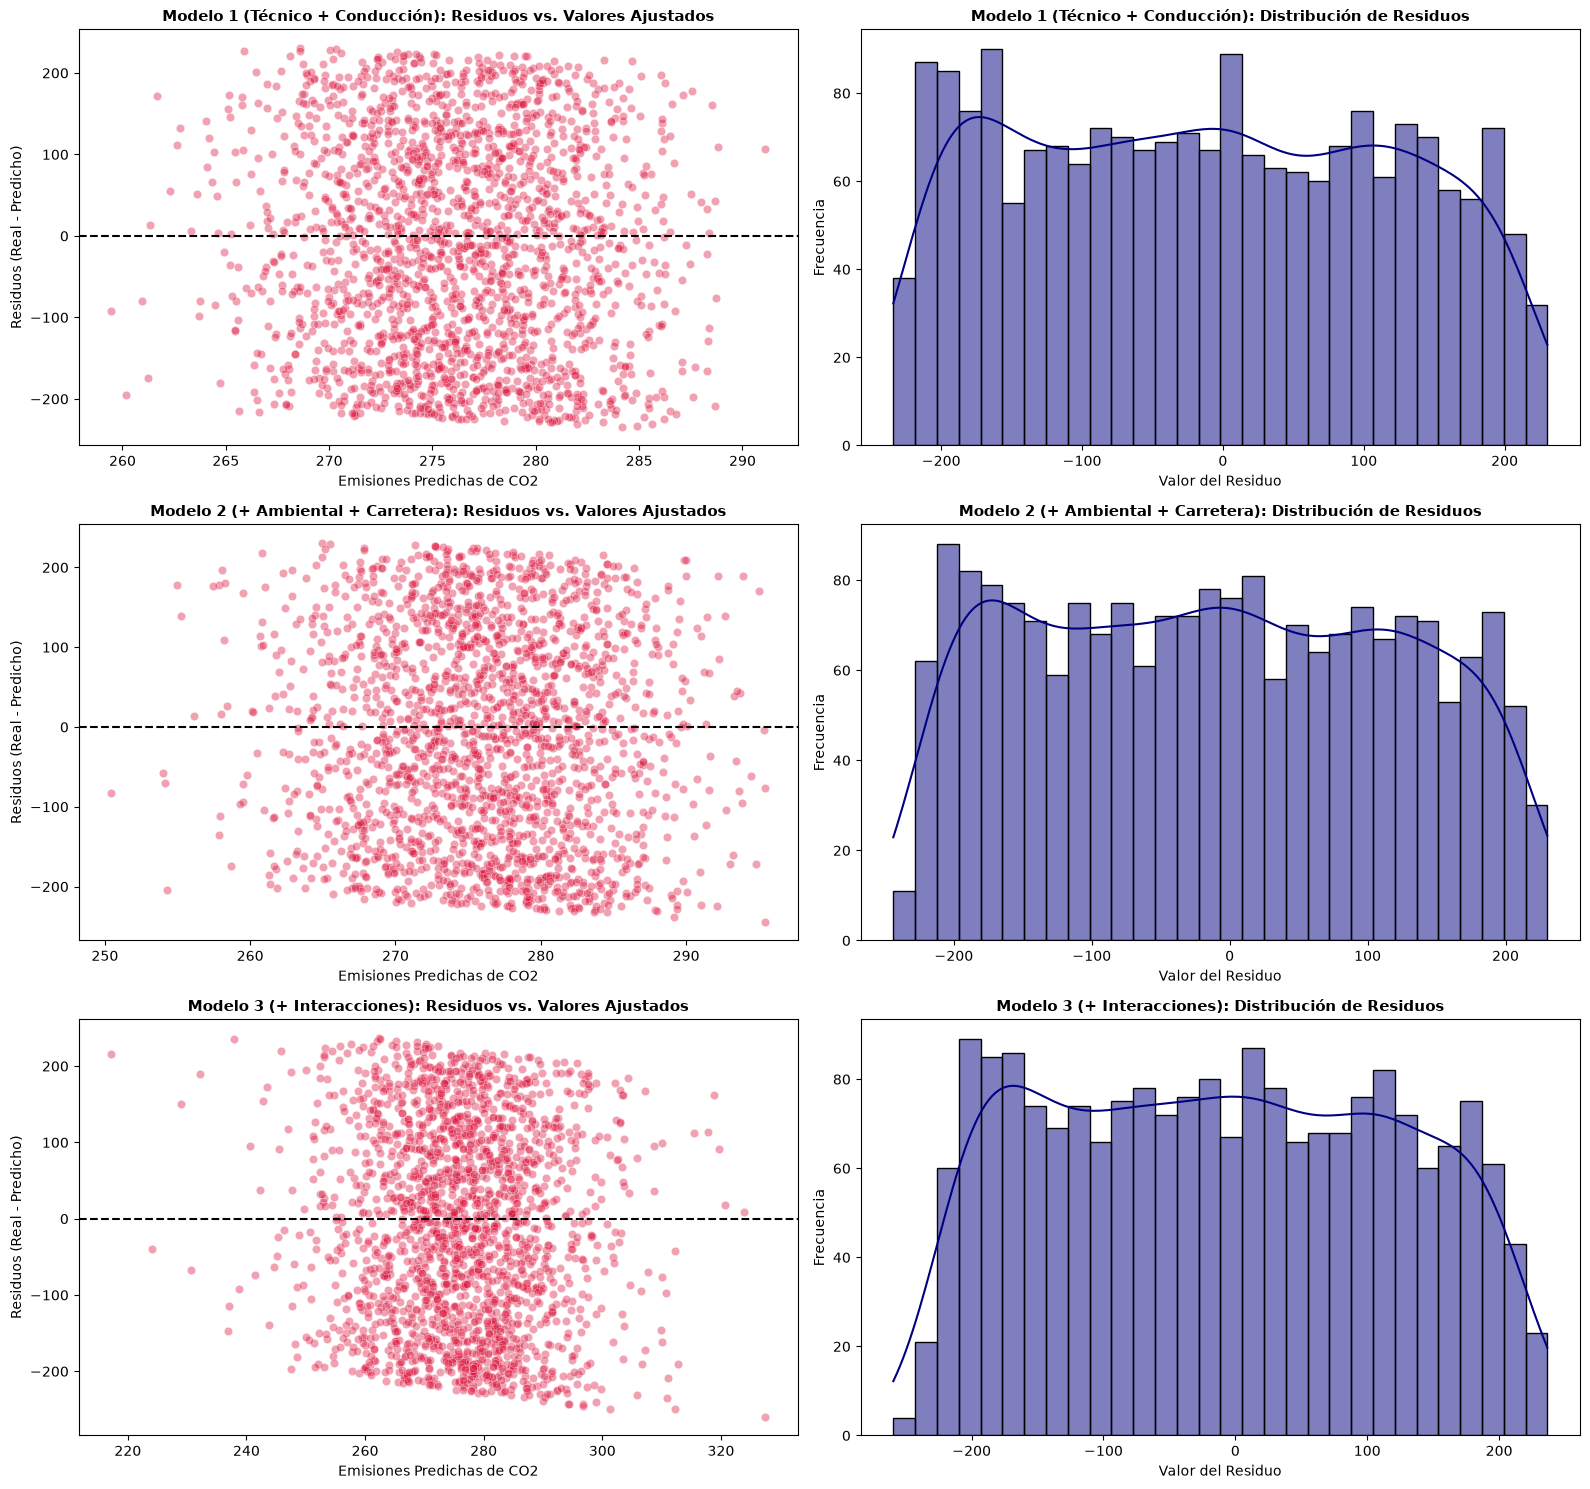

In [187]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

row = 0
for model_name, (prep, X_tr_subset, X_te_subset) in preprocessors.items():
    X_tr_proc = prep.fit_transform(X_tr_subset)
    X_te_proc = prep.transform(X_te_subset)
    
    model_ols = LinearRegression()
    model_ols.fit(X_tr_proc, y_train)
    
    y_pred = model_ols.predict(X_te_proc)
    residuals = y_test - y_pred
    
    sns.scatterplot(x=y_pred, y=residuals, ax=axes[row, 0], alpha=0.4, color='crimson')
    axes[row, 0].axhline(0, color='black', linestyle='--')
    axes[row, 0].set_title(f'{model_name}: Residuos vs. Valores Ajustados', fontsize=11, fontweight='bold')
    axes[row, 0].set_xlabel('Emisiones Predichas de CO2')
    axes[row, 0].set_ylabel('Residuos (Real - Predicho)')
    
    sns.histplot(residuals, kde=True, ax=axes[row, 1], color='navy', bins=30)
    axes[row, 1].set_title(f'{model_name}: Distribución de Residuos', fontsize=11, fontweight='bold')
    axes[row, 1].set_xlabel('Valor del Residuo')
    axes[row, 1].set_ylabel('Frecuencia')
    
    row += 1

plt.tight_layout()
plt.show()